# AeroRUL — Phase 5.1: Final Evaluation Audit, Error Analysis & Report Reconciliation

This notebook provides an interactive, reproducible audit and verification walkthrough of **Phase 5** results:
1. **Artifact Inventory & Manifest Audit**: Verifying frozen model configurations, hyperparameter fidelity, and preprocessing integrity.
2. **Official Test Endpoint Coverage**: Verifying 100% causal feature coverage across all 707 test engines without future leakage.
3. **Independent Metric Recalculation**: Independently calculating MAE, RMSE, $R^2$, Signed Error, and NASA asymmetric scores against official ground truth.
4. **Investigation of Large NASA Scores**: Explaining the mathematical and physical causes behind the large penalties in FD003 and FD004 (Pareto concentration and overprediction on early truncations).
5. **Signed Error & Directional Bias**: Resolving contradictions in the historical report narrative regarding underprediction vs overprediction.
6. **Degradation Phase Analysis**: Evaluating model performance across physical operational regimes ($RUL \le 30$ Critical, $31-75$ Low, $76-125$ Moderate, $>125$ High).
7. **Window Configuration & Target Cap Reconciliation**: Documenting evidence-based rationale for model selections (e.g., W75 for FD002, Cap=150 vs Cap=None).
8. **Interactive Visualizations**: Inspecting residual distributions, actual vs predicted regressions, and Pareto cumulative penalty curves.

> **Verification & Audit Only**: As per engineering protocol, no models are retrained, no hyperparameters are tuned, and no test labels are used for model selection.

## 1. Environment & Setup

In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import AVAILABLE_SUBSETS, REPORTS_DIR, RAW_DATA_DIR
from src.metrics import mae, rmse, r2_score, mean_signed_error, nasa_score

PHASE5_DIR = REPORTS_DIR / "phase5"
PHASE5_1_DIR = REPORTS_DIR / "phase5_1"
PHASE5_1_FIGURES_DIR = PHASE5_1_DIR / "figures"

print("Project root:", PROJECT_ROOT)
print("Available subsets:", AVAILABLE_SUBSETS)

Project root: C:\Users\himan\OneDrive\Documents\AeroRUL
Available subsets: ('FD001', 'FD002', 'FD003', 'FD004')


## 2. Frozen Configuration & Manifest Verification

In [2]:
manifest_audit_path = PHASE5_1_DIR / "final_manifest_audit.csv"
if manifest_audit_path.exists():
    df_manifest = pd.read_csv(manifest_audit_path)
    print("Frozen Model Manifest Audit Status:")
    display(df_manifest[["dataset", "manifest_model", "saved_model", "manifest_target_cap", "manifest_feature_config", "status"]])
else:
    print("Manifest audit file not found. Run scripts/run_phase5_1_audit.py first.")

Frozen Model Manifest Audit Status:


,dataset,manifest_model,saved_model,manifest_target_cap,manifest_feature_config,status
0,FD001,LightGBM,LGBMRegressor,150.0,ALL_WINDOWS,VERIFIED
1,FD002,LightGBM,LGBMRegressor,150.0,W75,VERIFIED
2,FD003,LightGBM,LGBMRegressor,NaN,ALL_WINDOWS,VERIFIED
3,FD004,LightGBM,LGBMRegressor,NaN,ALL_WINDOWS,VERIFIED


## 3. Official Test Engine Coverage & Alignment

In [3]:
coverage_audit_path = PHASE5_1_DIR / "test_feature_coverage_audit.csv"
if coverage_audit_path.exists():
    df_coverage = pd.read_csv(coverage_audit_path)
    print("Official Test Engine Coverage (All 707 engines represented exactly once):")
    display(df_coverage[["dataset", "official_engines_expected", "official_engines_predicted", "engines_with_lt_75_cycles", "partial_history_coverage_pct", "coverage_status"]])

Official Test Engine Coverage (All 707 engines represented exactly once):


,dataset,official_engines_expected,official_engines_predicted,engines_with_lt_75_cycles,partial_history_coverage_pct,coverage_status
0,FD001,100,100,20,100.0,FULL_COVERAGE_100_PCT
1,FD002,259,259,59,100.0,FULL_COVERAGE_100_PCT
2,FD003,100,100,11,100.0,FULL_COVERAGE_100_PCT
3,FD004,248,248,41,100.0,FULL_COVERAGE_100_PCT


## 4. Independent Test Metric Recalculation

In [4]:
# Load independent recalculations
recalc_path = PHASE5_1_DIR / "independent_test_metric_recalculation.csv"
df_recalc = pd.read_csv(recalc_path)

display_cols = [
    "dataset", "n_engines", "recalculated_mae", "reported_mae",
    "recalculated_rmse", "reported_rmse",
    "recalculated_nasa_sum", "reported_nasa_sum",
    "recalculated_mean_signed_error", "median_signed_error", "verification_status"
]
print("Independent Recalculations vs Reported Phase 5 Metrics:")
display(df_recalc[display_cols])

Independent Recalculations vs Reported Phase 5 Metrics:


,dataset,n_engines,recalculated_mae,reported_mae,recalculated_rmse,reported_rmse,recalculated_nasa_sum,reported_nasa_sum,recalculated_mean_signed_error,median_signed_error,verification_status
0,FD001,100,11.434757,11.434757,15.685765,15.685765,5.898683e+02,5.898683e+02,4.074434,2.110059,EXACT_MATCH
1,FD002,259,13.783750,13.783750,20.127055,20.127055,2.306695e+03,2.306695e+03,-1.218151,-0.486382,EXACT_MATCH
2,FD003,100,14.680725,14.680725,25.002669,25.002669,6.697540e+04,6.697540e+04,11.582277,3.073332,EXACT_MATCH
3,FD004,248,22.812514,22.812514,33.801785,33.801785,1.139046e+06,1.139046e+06,11.638342,6.553979,EXACT_MATCH


## 5. Root Cause of Large NASA Scores in FD003 and FD004

The NASA asymmetric scoring function is:
$$d_i = \hat{y}_i - y_i$$
$$s_i = \begin{cases} e^{-d_i / 13} - 1, & d_i < 0 \quad (\text{Underprediction / Early Maintenance}) \\ e^{d_i / 10} - 1, & d_i \ge 0 \quad (\text{Overprediction / Delayed Maintenance}) \end{cases}$$

Notice that overprediction receives an exponential penalty with denominator $10$.
When an uncapped model ($Cap=\text{None}$) predicts $\hat{y} \approx 245$ on a run truncated at early cycles with true $y = 137$, $d_i = +108.0$, yielding:
$$s_i = e^{10.8} - 1 = 48,938!$$

In [5]:
top_penalties_path = PHASE5_1_DIR / "top_nasa_penalties.csv"
df_top = pd.read_csv(top_penalties_path)

print("Top 5 Engine Penalties in FD003 (Uncapped Target, High Overprediction):")
display(df_top[df_top["dataset"] == "FD003"].head(5)[["dataset", "unit_id", "actual_rul_official", "predicted_rul_final", "signed_error", "individual_nasa_score", "penalty_share_pct"]])

print("\nTop 5 Engine Penalties in FD004 (Multi-Condition, Uncapped Target):")
display(df_top[df_top["dataset"] == "FD004"].head(5)[["dataset", "unit_id", "actual_rul_official", "predicted_rul_final", "signed_error", "individual_nasa_score", "penalty_share_pct"]])

Top 5 Engine Penalties in FD003 (Uncapped Target, High Overprediction):


,dataset,unit_id,actual_rul_official,predicted_rul_final,signed_error,individual_nasa_score,penalty_share_pct
40,FD003,74,117.0,224.983285,107.983285,48937.931554,73.068515
41,FD003,61,129.0,223.456196,94.456196,12651.620545,18.889951
42,FD003,27,88.0,164.840196,76.840196,2172.338235,3.243487
43,FD003,52,120.0,192.314316,72.314316,1381.199857,2.062249
44,FD003,54,87.0,155.166336,68.166336,911.906581,1.361554



Top 5 Engine Penalties in FD004 (Multi-Condition, Uncapped Target):


,dataset,unit_id,actual_rul_official,predicted_rul_final,signed_error,individual_nasa_score,penalty_share_pct
60,FD004,10,162.0,292.986507,130.986507,488282.150009,42.867624
61,FD004,229,120.0,248.178456,128.178456,368738.441899,32.372555
62,FD004,109,126.0,244.241347,118.241347,136506.487418,11.984277
63,FD004,104,120.0,228.675796,108.675796,52447.110296,4.604475
64,FD004,128,126.0,227.822541,101.822541,26428.974697,2.320272


## 6. Directional Bias & Residual Analysis

The signed error is defined as $e_i = \hat{y}_i - y_i$.
- **Positive ($e_i > 0$):** Model overpredicts remaining life (maintenance delayed).
- **Negative ($e_i < 0$):** Model underpredicts remaining life (early maintenance).

The Phase 5 report incorrectly claimed that multi-condition subsets exhibit 'conservative underprediction'.
Our audit reveals that FD003 and FD004 exhibit a systematic **overprediction bias** of $+11.58$ and $+11.64$ cycles.

In [6]:
contribs_path = PHASE5_1_DIR / "nasa_score_contributions.csv"
df_contribs = pd.read_csv(contribs_path)

summary_bias = []
for subset in AVAILABLE_SUBSETS:
    sub = df_contribs[df_contribs["dataset"] == subset]
    n = len(sub)
    n_over = int((sub["signed_error"] > 0).sum())
    n_under = int((sub["signed_error"] < 0).sum())
    summary_bias.append({
        "Dataset": subset,
        "Engines": n,
        "Mean Signed Error": sub["signed_error"].mean(),
        "Median Signed Error": sub["signed_error"].median(),
        "Overpredicting Units": f"{n_over} ({n_over/n*100:.1f}%)",
        "Underpredicting Units": f"{n_under} ({n_under/n*100:.1f}%)",
        "Empirical Bias": "Overpredicting" if sub["signed_error"].mean() > 0 else "Underpredicting"
    })

display(pd.DataFrame(summary_bias))

,Dataset,Engines,Mean Signed Error,Median Signed Error,Overpredicting Units,Underpredicting Units,Empirical Bias
0,FD001,100,4.074434,2.110059,56 (56.0%),44 (44.0%),Overpredicting
1,FD002,259,-1.218151,-0.486382,124 (47.9%),135 (52.1%),Underpredicting
2,FD003,100,11.582277,3.073332,73 (73.0%),27 (27.0%),Overpredicting
3,FD004,248,11.638342,6.553979,153 (61.7%),95 (38.3%),Overpredicting


## 7. Performance by Physical Degradation Phase (True-RUL Bins)

Descriptive breakdown of endpoint predictions by true remaining life:
- **Critical Phase ($0-30$ cycles):** Near-failure operational regime where maintenance must be scheduled.
- **Low Phase ($31-75$ cycles):** Advanced degradation.
- **Moderate Phase ($76-125$ cycles):** Intermediate degradation.
- **High Phase ($>125$ cycles):** Early life / minimal degradation.

In [7]:
range_path = PHASE5_1_DIR / "test_error_by_rul_range.csv"
df_range = pd.read_csv(range_path)

display(df_range[["dataset", "rul_bin", "engine_count", "mae", "rmse", "mean_signed_error", "nasa_score_sum", "mean_nasa_score"]])

,dataset,rul_bin,engine_count,mae,rmse,mean_signed_error,nasa_score_sum,mean_nasa_score
0,FD001,Critical (0–30),25,2.694316,3.565555,0.947011,8.054351,0.322174
1,FD001,Low (31–75),18,8.690497,11.125389,3.287896,34.536721,1.918707
2,FD001,Moderate (76–125),46,17.704885,21.229982,8.779350,532.604363,11.578356
3,FD001,High (>125),11,9.569463,10.978488,-7.205827,14.672849,1.333895
4,FD002,Critical (0–30),61,2.499740,3.178048,0.295895,16.746287,0.274529
5,FD002,Low (31–75),59,10.409466,14.037586,5.140528,271.065698,4.594334
6,FD002,Moderate (76–125),82,16.728491,20.881345,8.593799,927.442607,11.310276
7,FD002,High (>125),57,25.116007,31.601600,-23.535675,1091.440646,19.148082
8,FD003,Critical (0–30),20,2.235548,2.762329,0.887503,4.935567,0.246778
9,FD003,Low (31–75),29,8.924220,13.400352,6.046042,117.512666,4.052161


## 8. Single Source of Truth: Verified Results Table

In [8]:
verified_results_path = PHASE5_1_DIR / "final_verified_results.csv"
df_verified = pd.read_csv(verified_results_path)

display(df_verified[[
    "dataset", "selected_model", "selected_target_cap", "selected_feature_configuration",
    "official_test_engine_count", "test_mae", "test_rmse", "test_r2",
    "mean_signed_error", "nasa_score_sum", "nasa_score_mean", "maximum_individual_nasa_score"
]])

,dataset,selected_model,selected_target_cap,selected_feature_configuration,official_test_engine_count,test_mae,test_rmse,test_r2,mean_signed_error,nasa_score_sum,nasa_score_mean,maximum_individual_nasa_score
0,FD001,LightGBM,150.0,ALL_WINDOWS,100,11.434757,15.685765,0.857521,4.074434,5.898683e+02,5.898683,160.086795
1,FD002,LightGBM,150.0,W75,259,13.783750,20.127055,0.859932,-1.218151,2.306695e+03,8.906159,171.516724
2,FD003,LightGBM,NaN,ALL_WINDOWS,100,14.680725,25.002669,0.635192,11.582277,6.697540e+04,669.754017,48937.931554
3,FD004,LightGBM,NaN,ALL_WINDOWS,248,22.812514,33.801785,0.615667,11.638342,1.139046e+06,4592.929280,488282.150009


## 9. Key Diagnostic Visualizations

=== Actual vs Predicted RUL Regressions ===


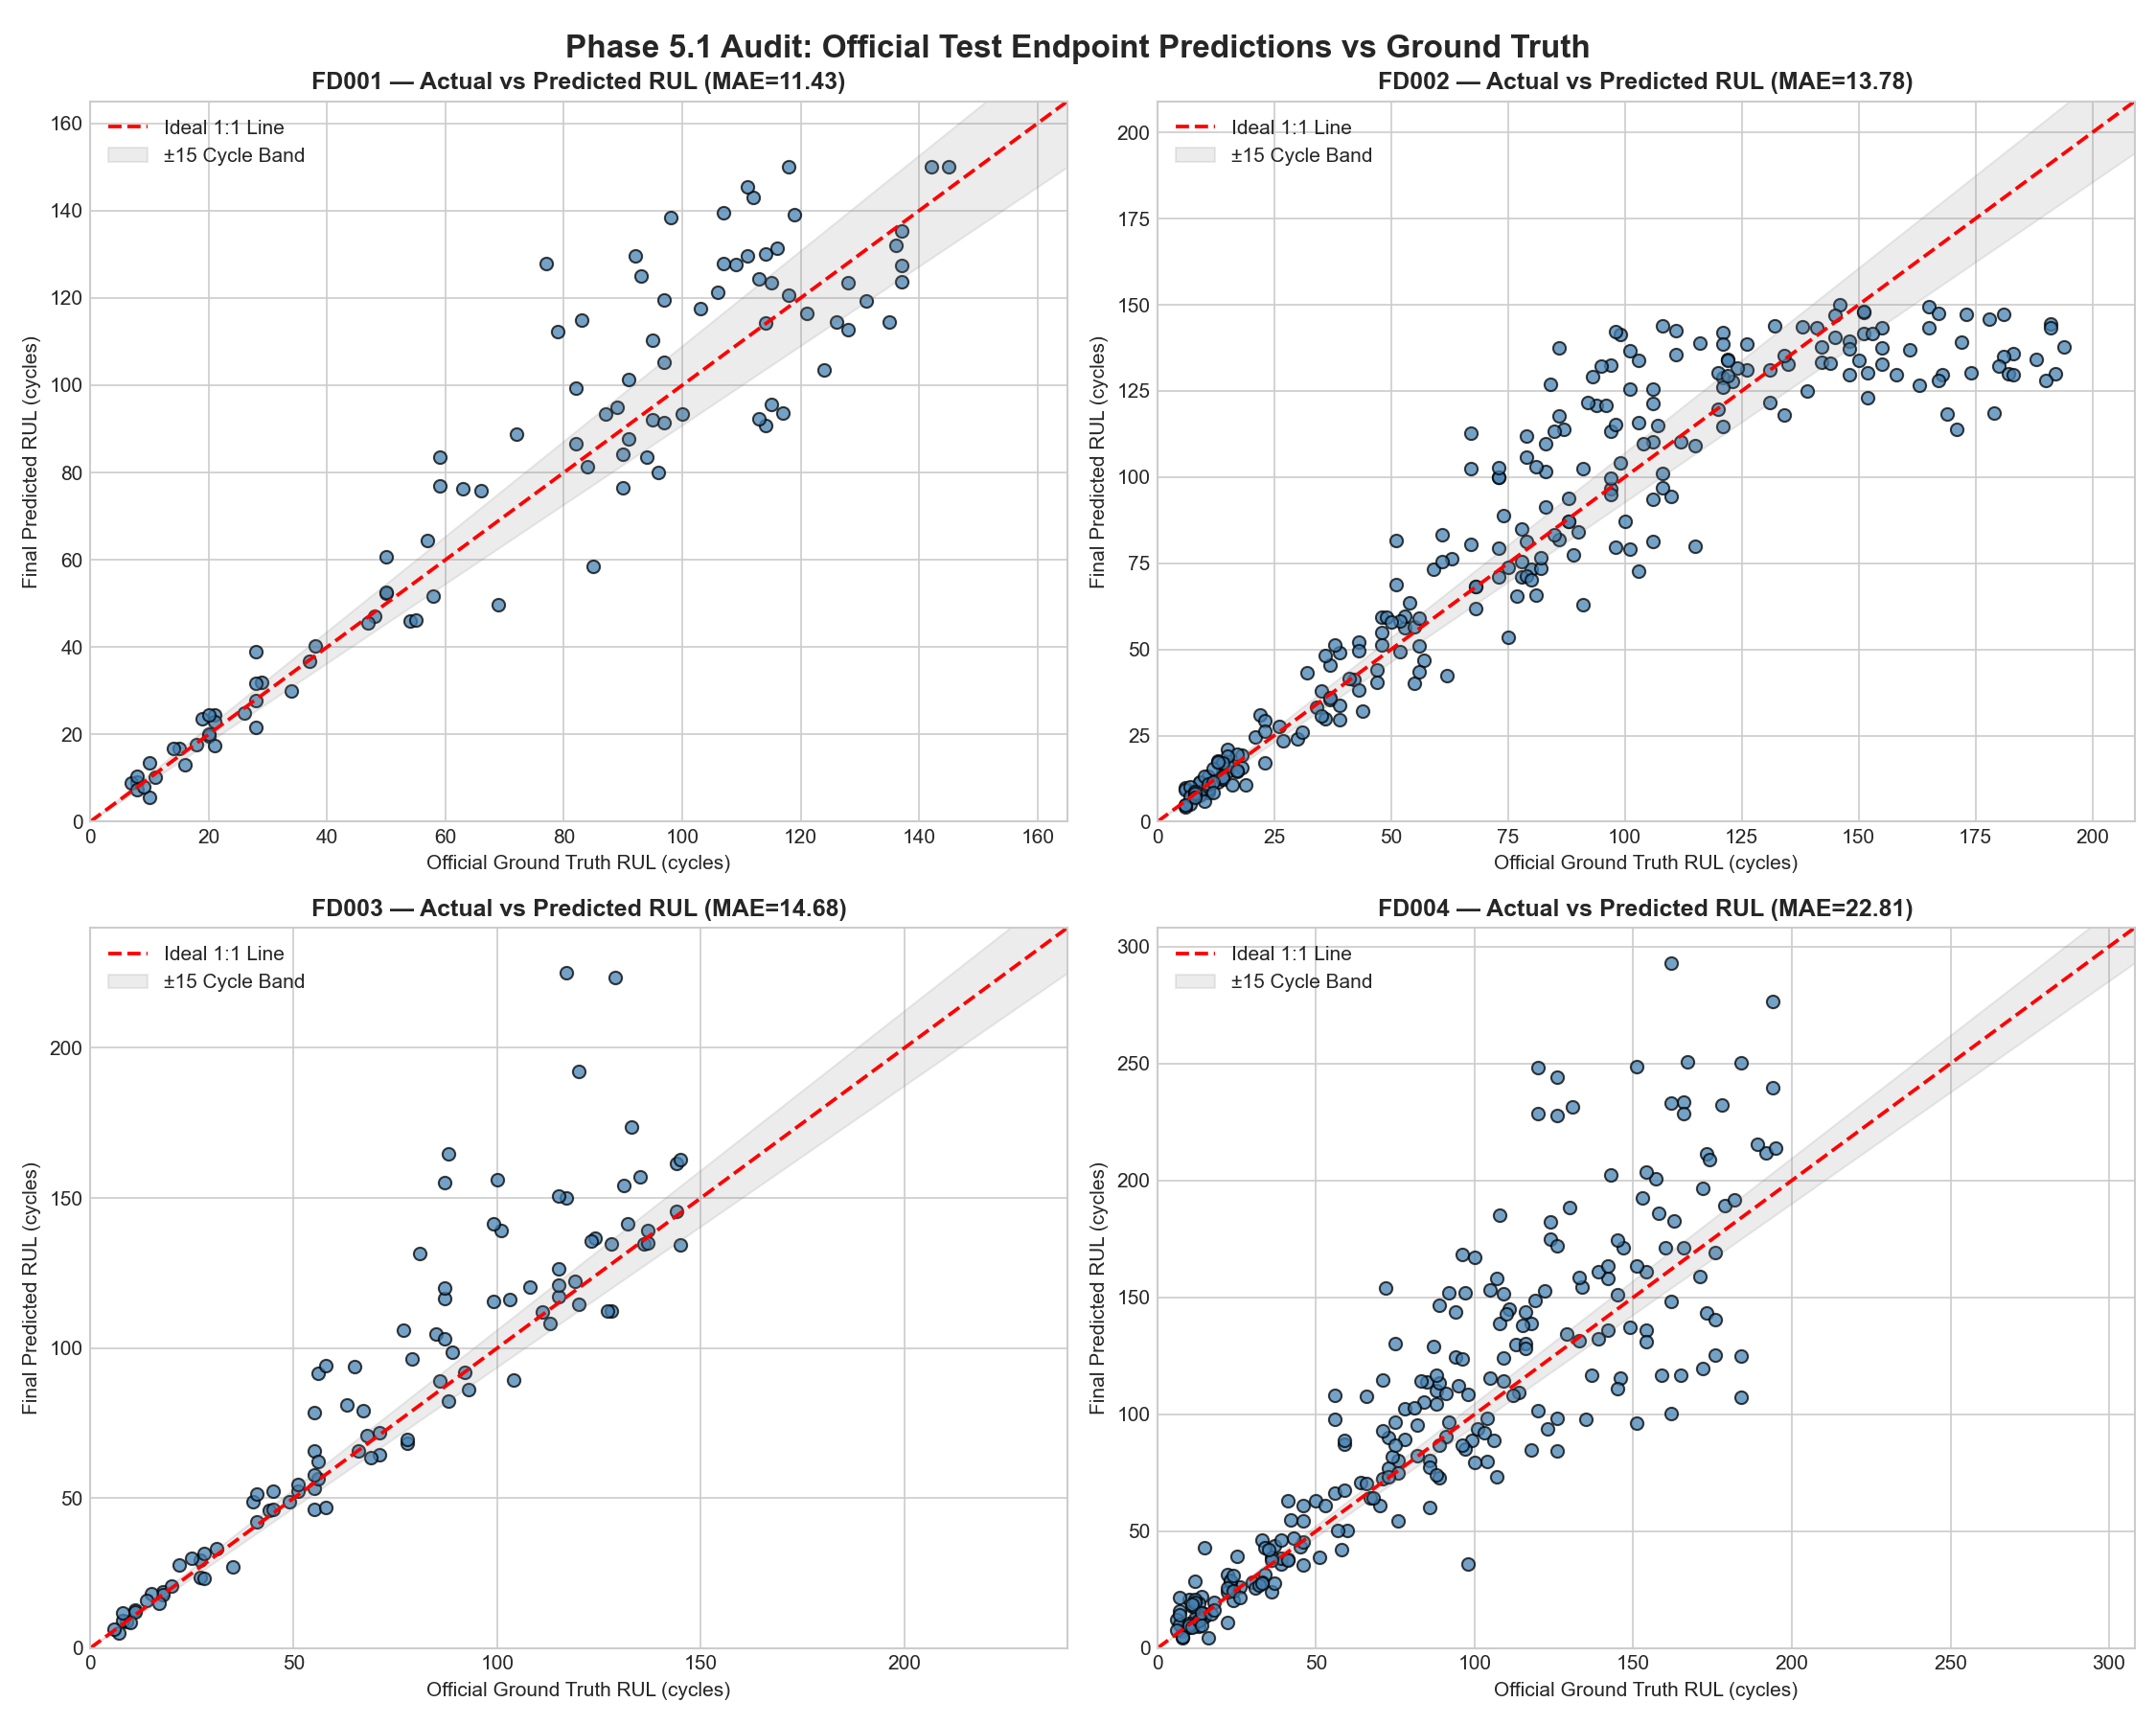

=== Residual Bias vs True RUL ===


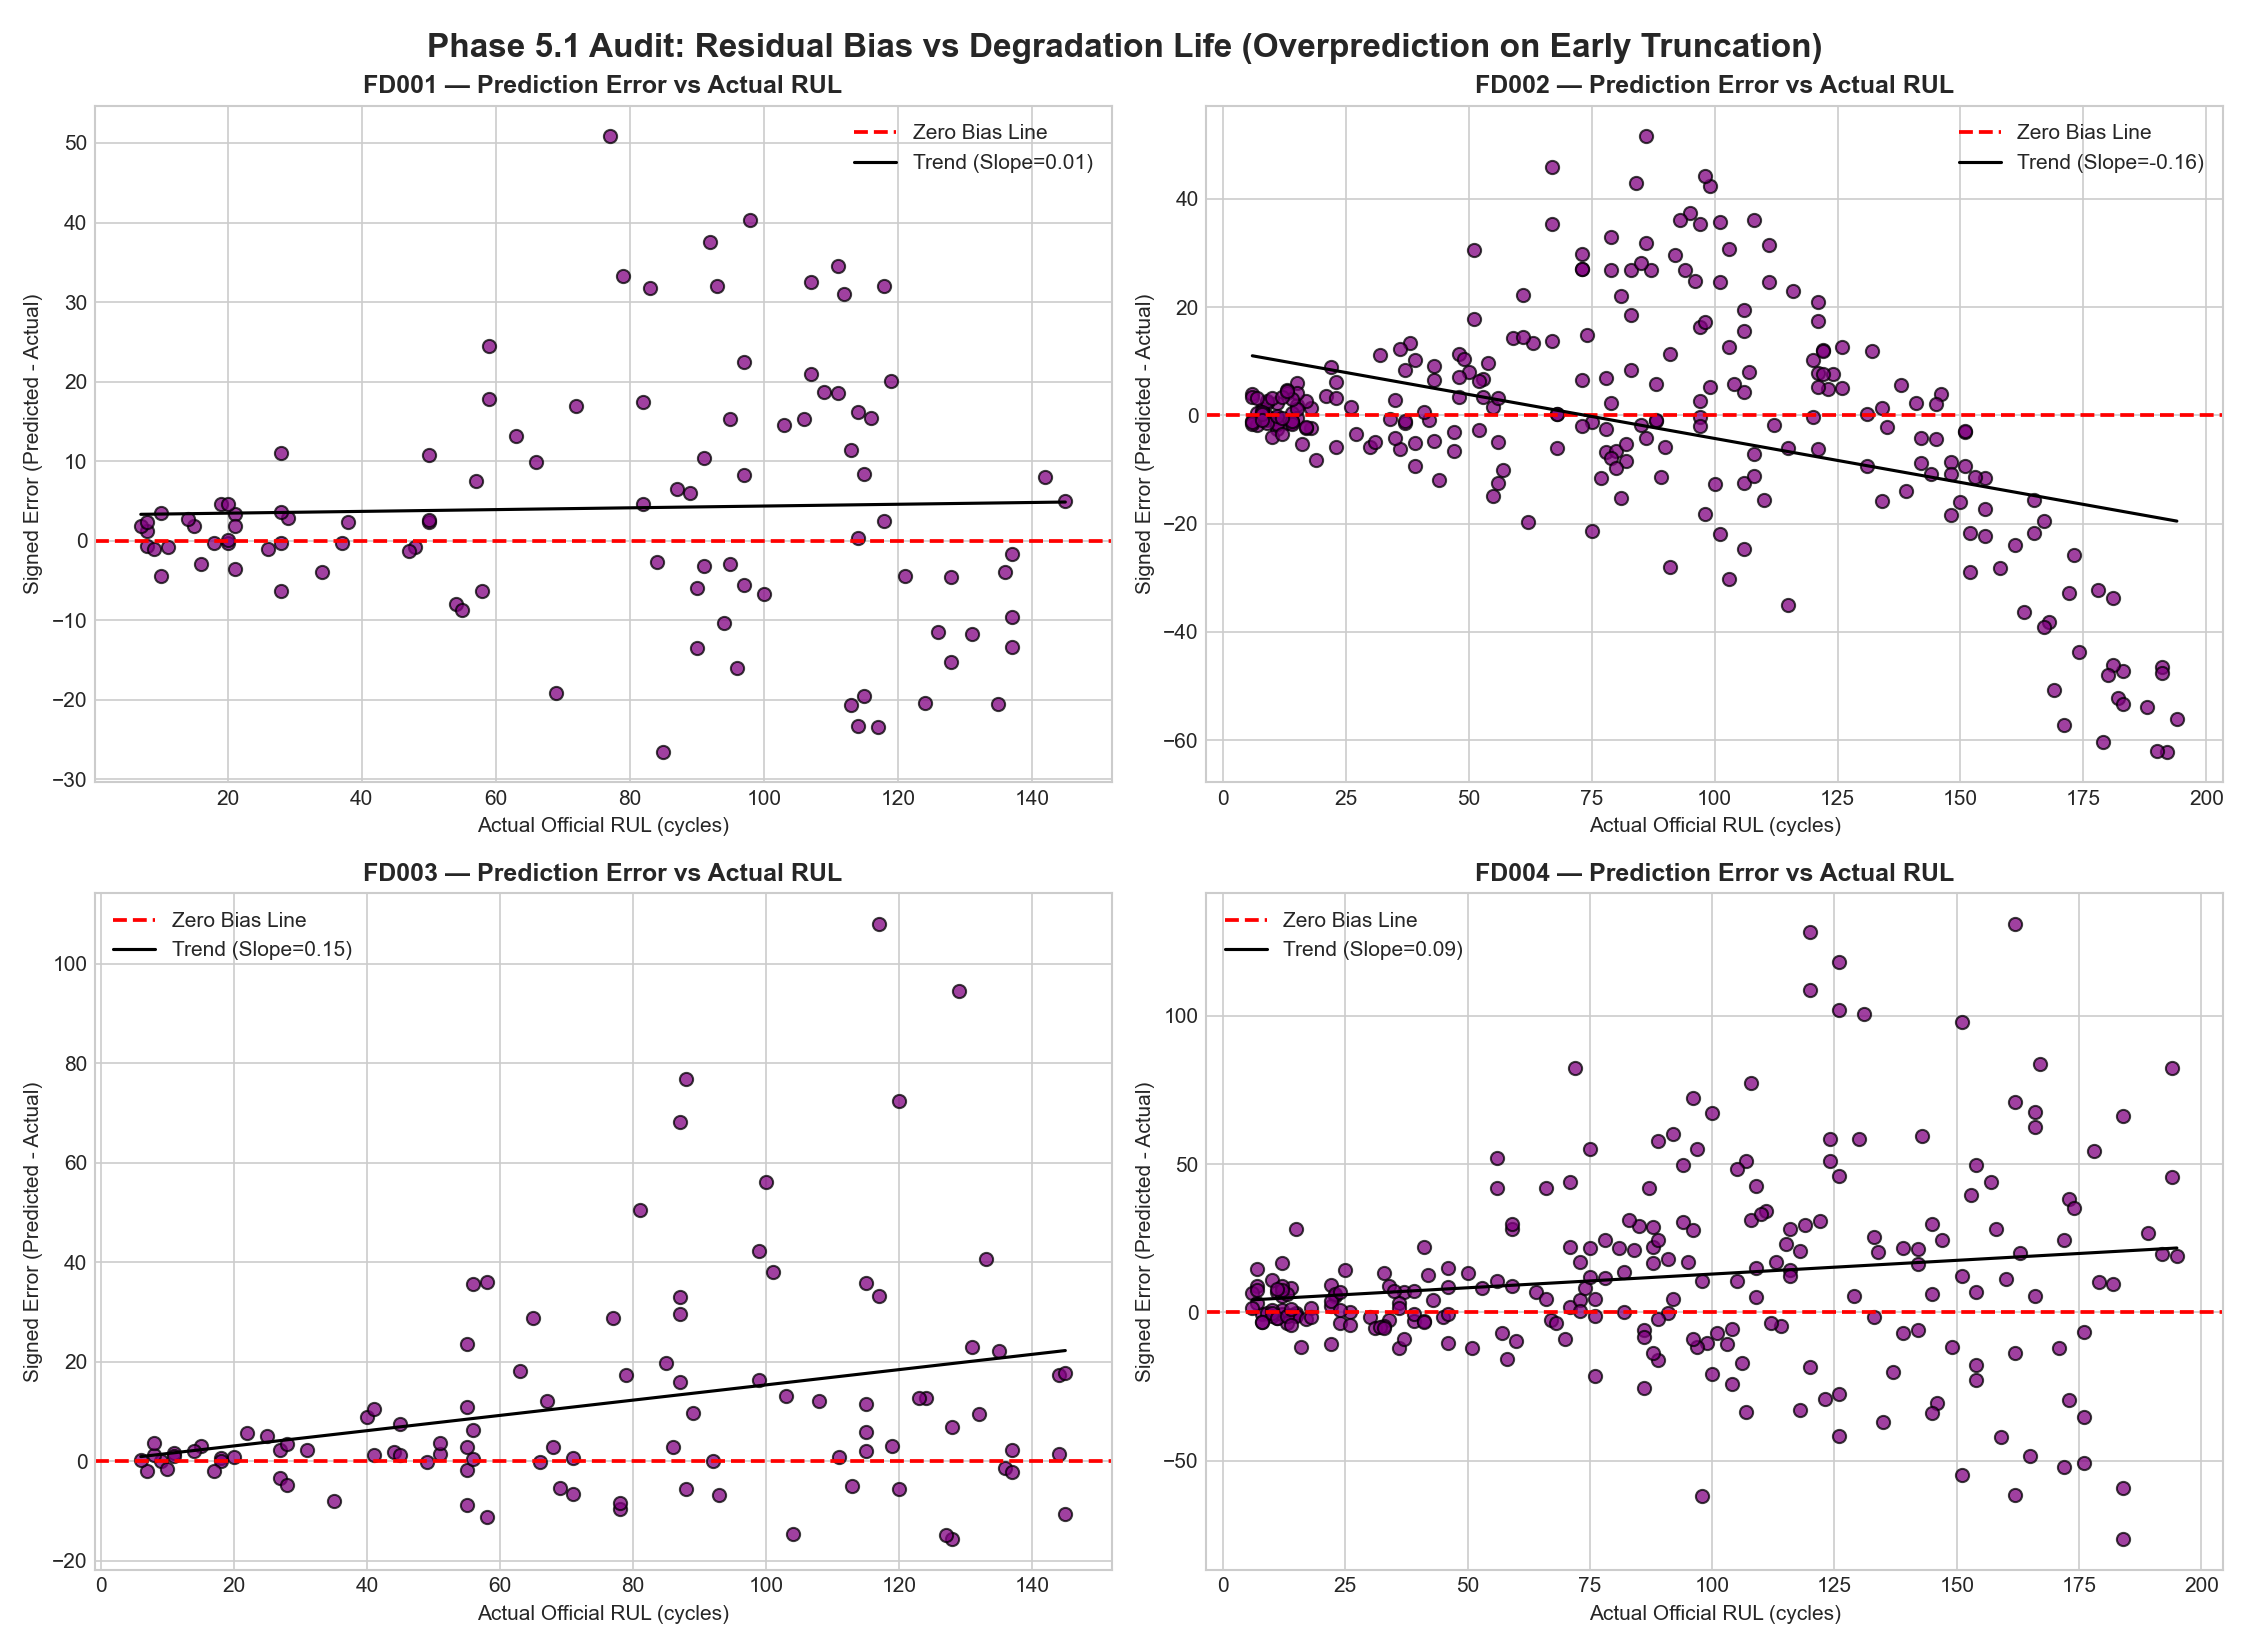

=== Cumulative Pareto NASA Penalty Concentration ===

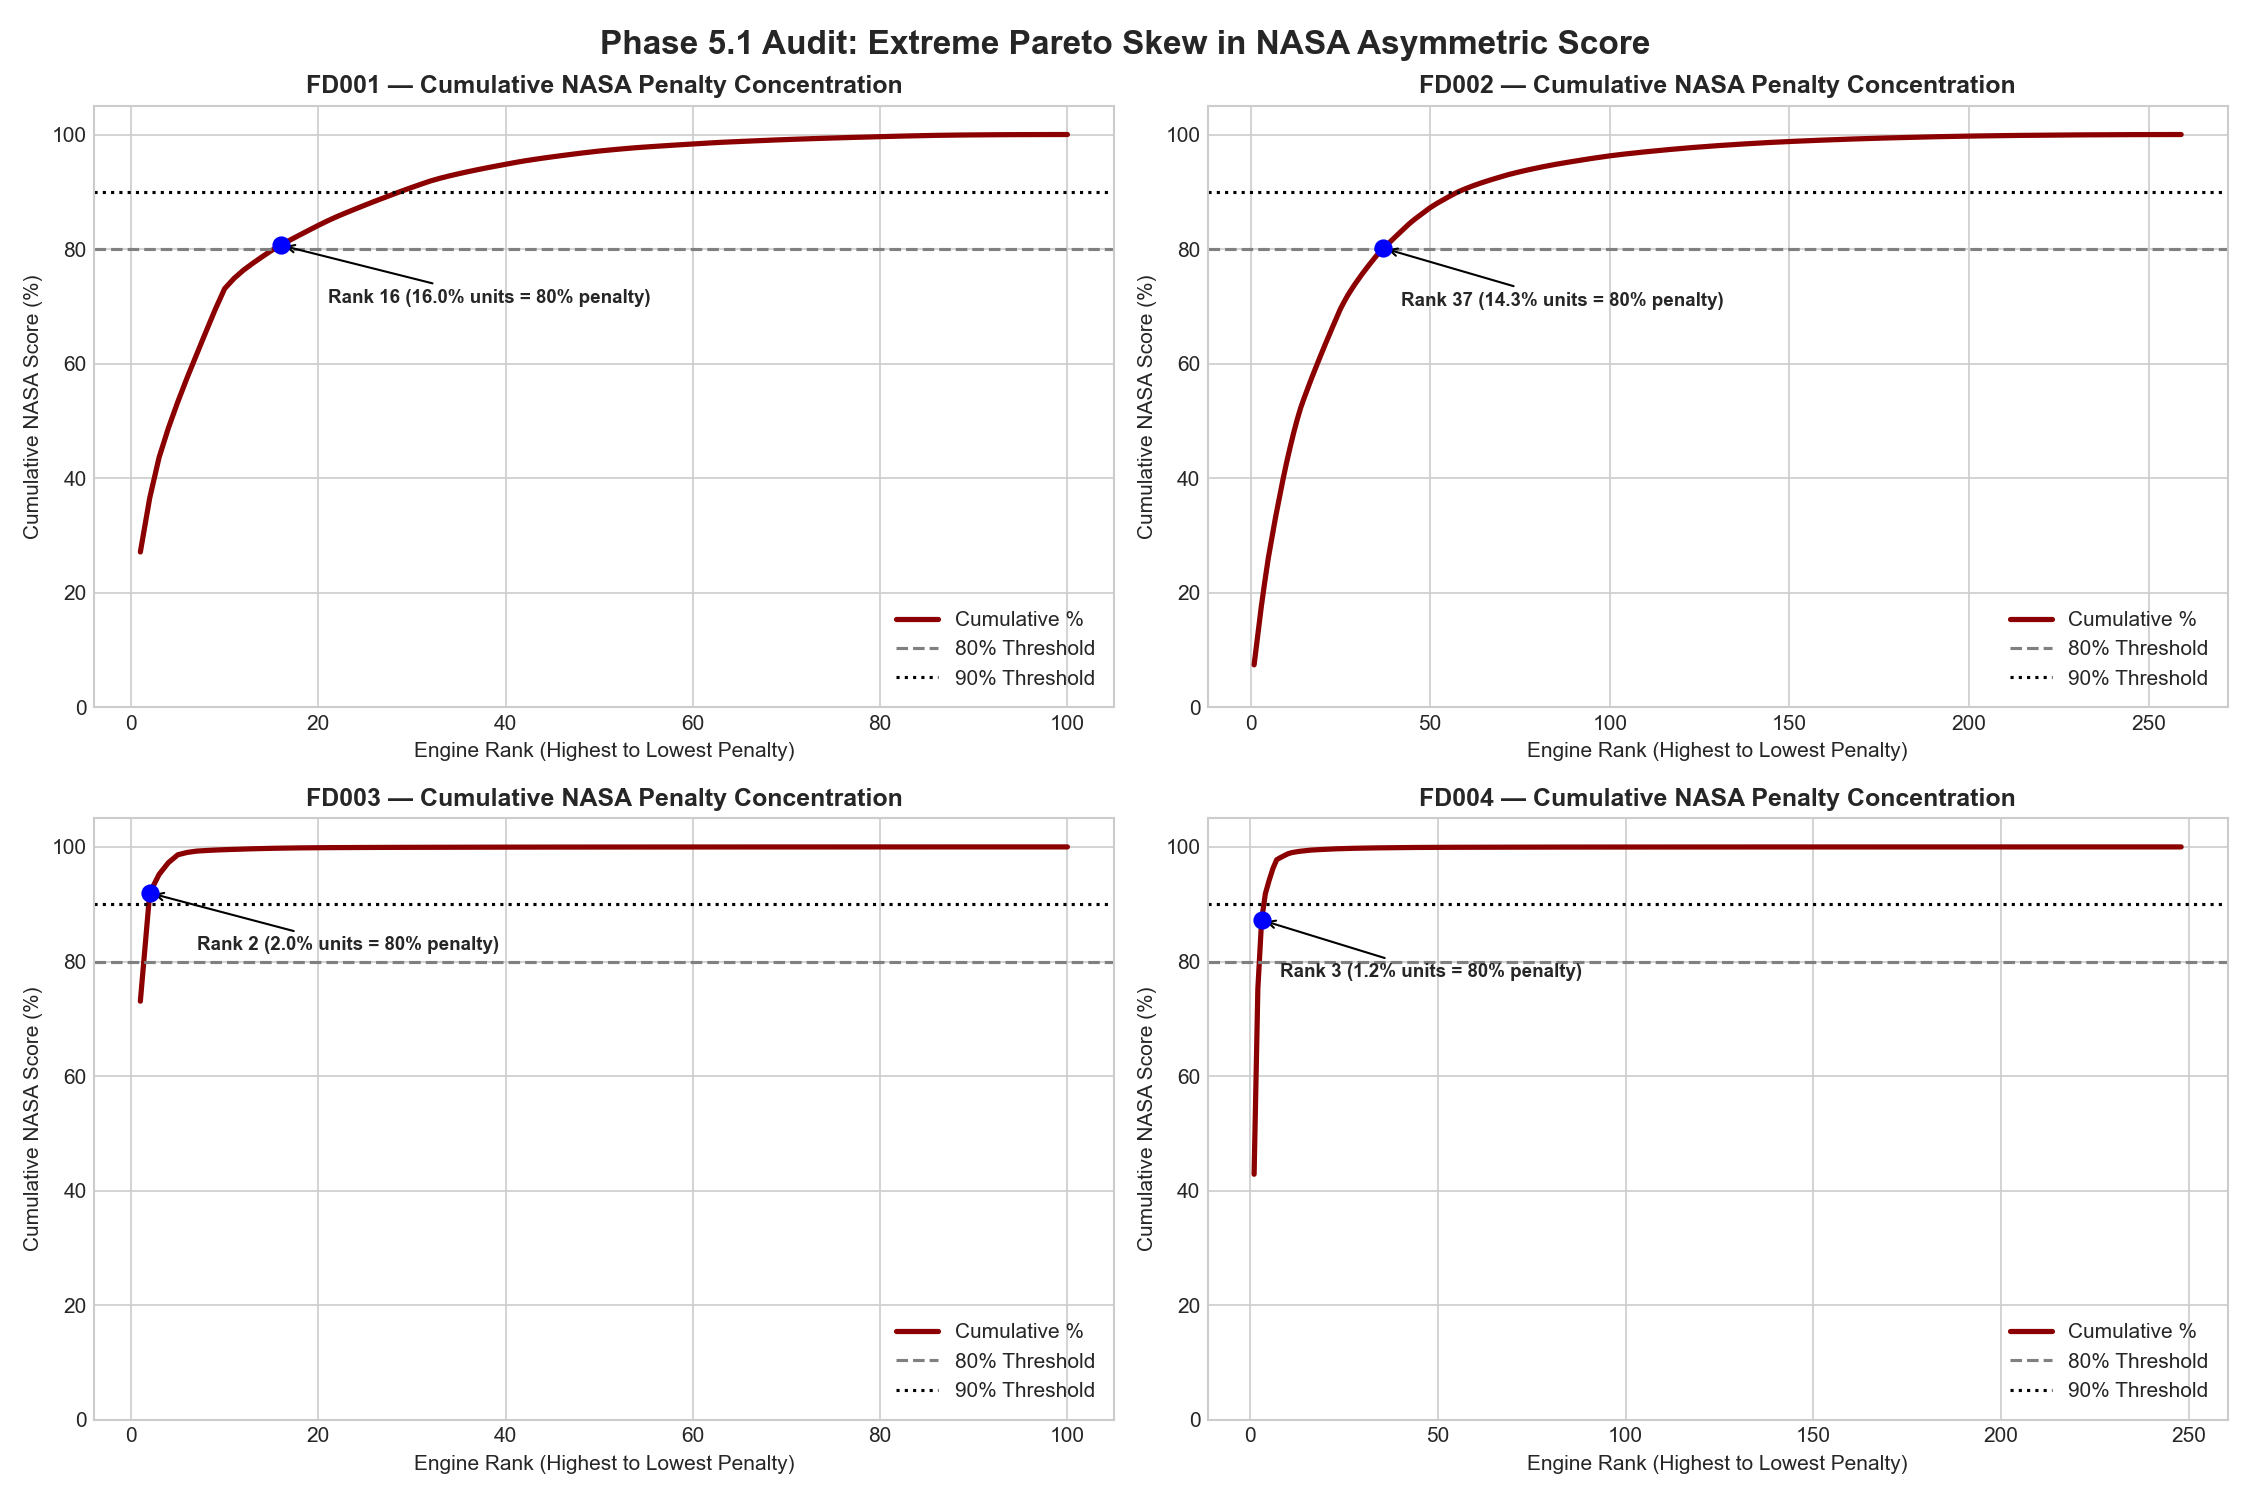

=== Error (MAE) Across Degradation Phases ===


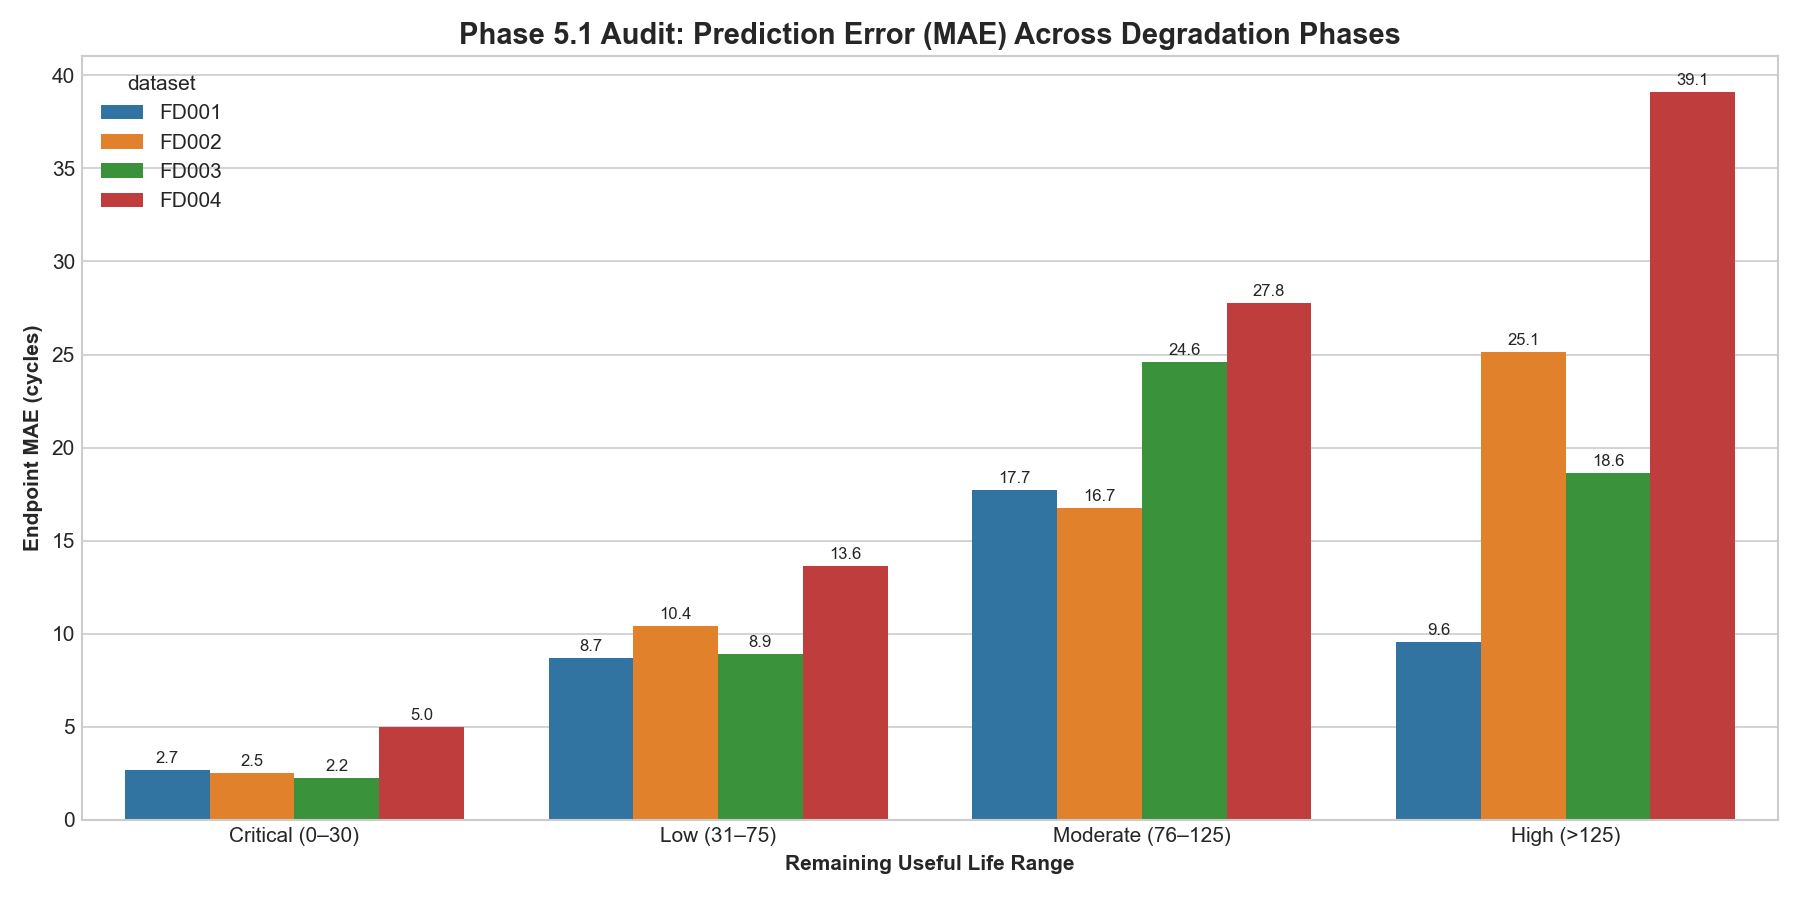

=== Mean vs Median Signed Error ===


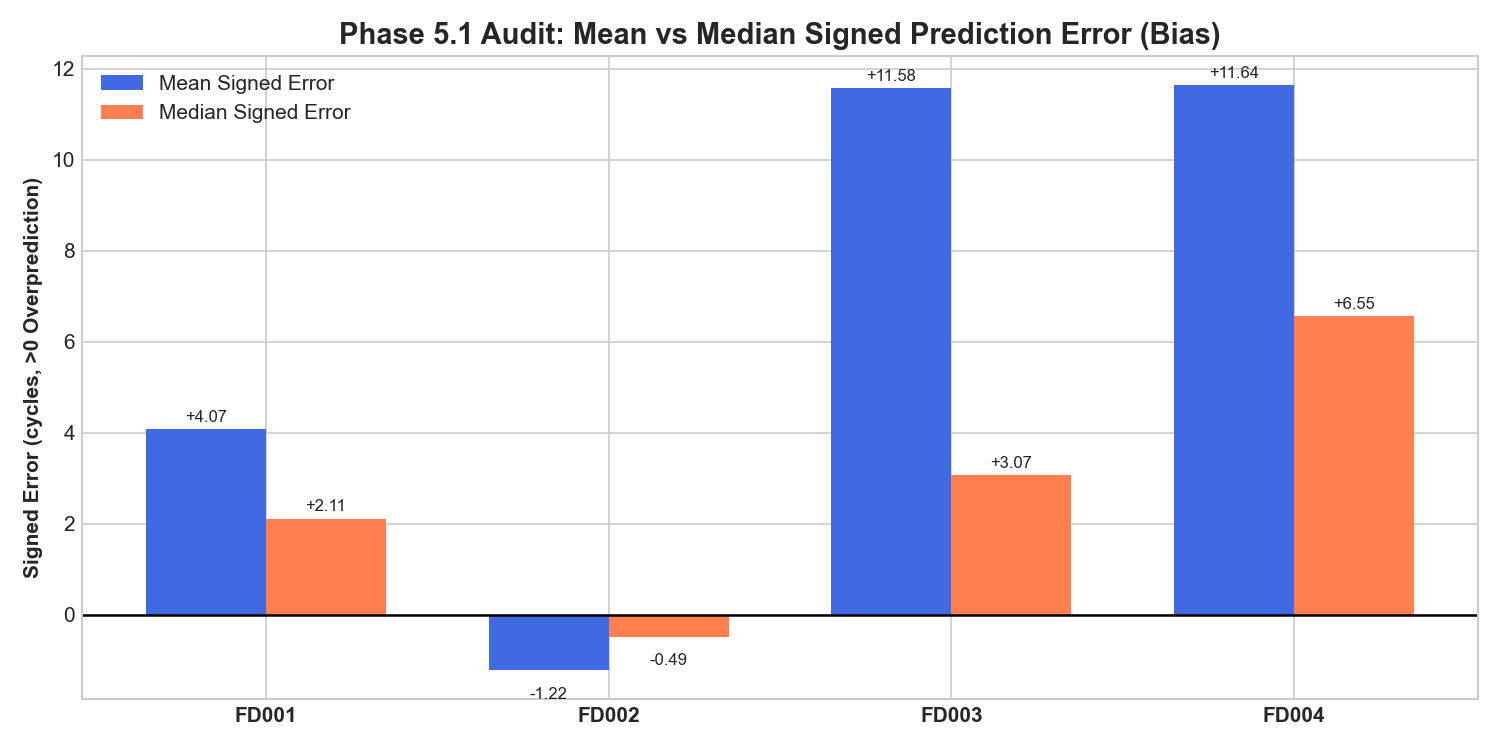

In [9]:
from IPython.display import Image, display

figures = [
    ("Actual vs Predicted RUL Regressions", PHASE5_1_FIGURES_DIR / "fig01_actual_vs_predicted.png"),
    ("Residual Bias vs True RUL", PHASE5_1_FIGURES_DIR / "fig03_residual_vs_actual.png"),
    ("Cumulative Pareto NASA Penalty Concentration", PHASE5_1_FIGURES_DIR / "fig06_nasa_penalty_ranking.png"),
    ("Error (MAE) Across Degradation Phases", PHASE5_1_FIGURES_DIR / "fig07_error_by_rul_range.png"),
    ("Mean vs Median Signed Error", PHASE5_1_FIGURES_DIR / "fig08_signed_error_comparison.png"),
]

for title, fpath in figures:
    if fpath.exists():
        print(f"=== {title} ===")
        display(Image(filename=str(fpath)))